In [1]:
import os
import numpy as np
import pandas as pd
import json 
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.patches import Rectangle
import seaborn as sns

from scipy.stats import mannwhitneyu, kruskal
from statsmodels.stats.multitest import fdrcorrection
from statannotations.Annotator import Annotator
import scikit_posthocs as sp
from itertools import combinations
from scipy.stats import pearsonr
from statsmodels.formula.api import ols
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

import itertools
from scipy.stats import chi2_contingency, fisher_exact

from morph_utils.query import get_id_by_name
from morph_utils.templates import load_layer_template
from neuron_morphology.swc_io import morphology_from_swc

import warnings

import sys 
sys.path.append('/root/capsule/code/figures') 
from core_utils import get_seaad_colors, format_box_plot


sns.set_context("notebook")
plt.rcParams['pdf.fonttype'] = 42 # ensures that the text is editable when imported into Illustrator


/opt/conda/lib/python3.10/site-packages/google/api_core/_python_version_support.py:254: FutureWarning: You are using a Python version (3.10.12) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


Box plots comparing macaque and human dendrite morphology features by Great Ape Consensus Taxonomy cluster 
And then comaring all species (adding mouse) at subclass level 
- Remove Layer Aligned features
- Remove axon only cells

In [2]:
species_type = 'primate' #species #primate 
dataset_type = '' #'_inclusive', ''  --- '' is restricted to L5 IT in Layer 5, '_inclusive' includes L5 IT not in Layer 5

In [3]:
depth_type = 'layer' # depth_in_layer_norm used to define superficial/deep L2/3 IT groups
# depth_type = 'pia' # depth_from_pia_norm used to define superficial/deep L2/3 IT groups


include_pseq_tea = False #whether to include Patch-seq TEa data

##################################
if depth_type == 'pia':
    depth_column = 'depth_from_pia_norm'
    #thresholds for defining superficial and deep from depth_from_pia_norm 
    lower_thresh = 0.15
    middle_thresh = 0.25
    upper_thresh = 0.45
else:
    depth_column = 'depth_in_layer_norm_new'
    #thresholds for defining superficial and deep from depth_in_layer_norm 
    lower_thresh = 0.2
    middle_thresh = 0.5
    upper_thresh = 1

In [4]:
#human
h_subclass_col = 'subclass_label_Hierarchical' #'subclass_Corr_label_RSC_122-389'
h_cluster_col = 'cluster_label_Hierarchical' #'cluster_Corr_label_RSC_122-389'

#macaque
p_subclass_col =  'subclass_Corr_label_RSC_204_389'
p_cluster_col =   'cluster_Corr_label_RSC_204_389'

#mouse
m_subclass_col =  'subclass'
m_cluster_col =  't_type'

#rename to
subclass_col =  'subclass'
cluster_col =   'cluster'

In [5]:
# Save root 
OUT_DIR = Path('/root/capsule/scratch') / '20260807' / 'species_comparison'
os.makedirs(OUT_DIR, exist_ok=True)

# Data paths
DATA_ROOT = Path('/root/capsule/data')

# HUMAN TemL
human_metadata_file =     DATA_ROOT / 'human' / 'metadata'   / '20260807' / 'human_metadata.csv'
human_feature_file =      DATA_ROOT / 'human' / 'morphology' / 'dendrite' / '20260712' / 'RawFeatureWide.csv'
human_swc_dir =           DATA_ROOT / 'human' / 'morphology' / 'swc'      / '20260625' / 'SWC_LayerAligned'
human_soma_depth_file =   DATA_ROOT / 'human' / 'soma_depth' / '20260827' / 'human_soma_depths.csv'

# MACAQUE TemL
macaque_metadata_file =         DATA_ROOT / 'macaque' / 'metadata'   / '20260722' / 'macaque_metadata.csv'
macaque_feature_file =          DATA_ROOT / 'macaque' / 'morphology' / 'dendrite' / '20260722' / 'RawFeatureWide.csv'
macaque_swc_dir =               DATA_ROOT / 'macaque' / 'morphology' / 'swc'      / '20260722' / 'SWC_LayerAligned'
macaque_soma_depth_file =       DATA_ROOT / 'macaque' / 'soma_depth' / '20260827' / 'macaque_soma_depths.csv'
macaque_average_layers_file =   DATA_ROOT / 'macaque' / 'average_cortical_layers' / '20250314' / 'macaque_average_layers.json'

# MOUSE TEa
mouse_metadata_file =     DATA_ROOT / 'mouse' / 'metadata'   / '20260826' / 'mouse_metadata.csv'
mouse_feature_file =      DATA_ROOT / 'mouse' / 'morphology' / 'dendrite' / '20260826' / f'RawFeatureWide{dataset_type}.csv' # 'RawFeatureWide_inclusive.csv'
mouse_swc_dir =           DATA_ROOT / 'mouse' / 'morphology' / 'swc'      / '20260826' / 'SWC_LayerAligned'

# depth alignment
l23_grouping_file =         OUT_DIR / f'l23_comparison_{depth_type}.csv'

#colors
color_file = DATA_ROOT / 'colors' / 'HMBA_colors.csv'

#subclass order
subclass_order_file =         DATA_ROOT / 'formatting_dicts' / 'subclass_order.txt'


In [6]:
# HUMAN TemL
human_metadata = pd.read_csv(human_metadata_file)
human_metadata[h_subclass_col] = human_metadata[h_subclass_col].replace('L5 ET_ME', 'L5 ET').replace('L5 ET(ME)', 'L5 ET')
human_metadata[h_cluster_col] = human_metadata[h_cluster_col].replace('L5 ET_ME', 'L5 ET(ME)')
human_metadata = human_metadata[human_metadata.lobe == 'TemL']
human_raw_feature_wide = pd.read_csv(human_feature_file)
human_metadata = human_metadata.rename(columns={h_subclass_col: subclass_col, h_cluster_col: cluster_col, 'cell_id': 'specimen_id'})
human_metadata = human_metadata.dropna(subset=[subclass_col, cluster_col])
human_metadata['species'] = 'human'

#MACAQUE TemL
macaque_metadata = pd.read_csv(macaque_metadata_file)
macaque_metadata = macaque_metadata[macaque_metadata.Morphology == True]
macaque_raw_feature_wide = pd.read_csv(macaque_feature_file)
macaque_metadata = macaque_metadata[macaque_metadata.specimen_id.isin(macaque_raw_feature_wide.specimen_id.tolist())]
macaque_metadata = macaque_metadata.rename(columns={p_subclass_col: subclass_col, p_cluster_col: cluster_col})
macaque_metadata['species'] = 'macaque'

#MOUSE TEa
mouse_metadata = pd.read_csv(mouse_metadata_file)
mouse_raw_feature_wide = pd.read_csv(mouse_feature_file).rename(columns={'Unnamed: 0': 'specimen_id'})
mouse_metadata = mouse_metadata.rename(columns={m_subclass_col: subclass_col, m_cluster_col: cluster_col, 'Cell Specimen Id': 'specimen_id'})
mouse_metadata[subclass_col] = (
    mouse_metadata[subclass_col]
    .str.replace('-', '/', regex=False)
    .str.replace('_', ' ', regex=False)
)
mouse_metadata['species'] = 'mouse'
mouse_metadata[cluster_col] = 'Unknown'

#depth matching groups for L2/3 IT subclass
l23_grouping_data = pd.read_csv(l23_grouping_file)

#colors
color_df = pd.read_csv(color_file)
color_df = color_df[color_df.label.isin(['Human', 'Macaque', 'Mouse'])][['label', 'color_hex_triplet']]
species_colors = dict(zip(color_df['label'].str.lower(), color_df['color_hex_triplet']))
species_colors['mouse TEa'] = '#c9416a'
species_colors['mouse VIS'] = species_colors['mouse']

#get plotting color dict
color_dict = get_seaad_colors()
color_dict['L2/3 IT_superficial'] = color_dict['L2/3 IT']
color_dict['L2/3 IT_deep'] = color_dict['L2/3 IT']


In [7]:
cluster_var_name = subclass_col

#combine data 
human_data = human_metadata[['specimen_id', subclass_col, cluster_col, 'species']].merge(human_raw_feature_wide, how='inner', on='specimen_id')
macaque_data = macaque_metadata[['specimen_id', subclass_col, cluster_col, 'species']].merge(macaque_raw_feature_wide, how='inner', on='specimen_id')
mouse_data = mouse_metadata[['specimen_id', subclass_col, cluster_col, 'species']].merge(mouse_raw_feature_wide, how='inner', on='specimen_id')

#select region/species data to analyze
if species_type == 'species':
    data = pd.concat([human_data, macaque_data, mouse_data])
elif species_type == 'primate':
    data = pd.concat([human_data, macaque_data])
else: raise ValueError(f'Unknown species_type: {species_type}')

data['dendrite_total_length'] = data['apical_dendrite_total_length'] + data['basal_dendrite_total_length']

#drop axon columns (computed for TEa but shouldn't be included)
cols_to_drop = data.columns[data.isna().sum() >= 50]
data = data.drop(columns=cols_to_drop)

In [8]:
if species_type == 'species':
    #restrict data to L5 for including this mouse TEa dataset (it doesn't have enough L2/3 cells to compare)
    data = data[data.subclass.isin(['L5 IT', 'L5 ET'])]
elif species_type == 'primate':
    data = data[data.subclass.isin(['L2/3 IT', 'L5 IT',  'L5/6 NP', 'L5 ET'])]
else: raise ValueError(f'Unknown species_type: {species_type}')


In [9]:
data.subclass.value_counts()

L2/3 IT    126
L5 IT       45
L5 ET       23
L5/6 NP     14
Name: subclass, dtype: int64

In [10]:
len(data)

208

In [11]:
# L2/3 IT subclass depth mathing 
l23_grouping_col = 'depth_group_two' 

#append the grouping to L2/3 IT subclass name (i.e. '_superficial', '_deep')
id_to_group = l23_grouping_data.set_index('specimen_id')[l23_grouping_col]
mask = data.specimen_id.isin(id_to_group.index)
data.loc[mask, 'subclass'] = (
    data.loc[mask, 'subclass'] + '_' + data.loc[mask, 'specimen_id'].map(id_to_group)
)

data = data[data.subclass != 'L2/3 IT'] # remove the L2/3 IT cells that did not have a depth match, these are < 0.2 normalized depth, and so are likely Layer 2 cells (macaque doesn't have any)

In [12]:
len(data)

162

In [13]:
tdl_medians = {}
for subclass in data.subclass.unique():
    tdl_medians[subclass] = {}
    for species_val in data.species.unique():
        tdl_medians[subclass][species_val] = data[(data.subclass == subclass) * (data.species == species_val)]['dendrite_total_length'].median()

#save
with open(os.path.join(OUT_DIR, f'{species_type}_subclass_dendrite_total_length_medians.json'), 'w') as f:
    json.dump(tdl_medians, f, indent=4)

In [14]:
#featrure differentiation 
keywords = ('apical', 'basal', 'axon', 'soma', 'dendrite')
feature_cols = [c for c in data.columns if any(k in c for k in keywords)]
meta_cols = [c for c in data.columns if not c in feature_cols]


In [15]:
len(feature_cols)

52

In [16]:
#cluster order 
subclass_order = pd.read_csv(subclass_order_file, header=None, names=['cluster'])['cluster'].tolist()
index = subclass_order.index('L2/3 IT')
subclass_order = subclass_order[:index] + ['L2/3 IT_superficial', 'L2/3 IT_intermediate', 'L2/3 IT_deep'] + subclass_order[index+1:]
subclass_order = [c for c in subclass_order if c in data['subclass'].unique()]

In [17]:
data.to_csv(os.path.join(OUT_DIR, f'{species_type}_subclass_data.csv'), index=False)

Box plots 

In [18]:
x_var = 'subclass'
x_var_order = subclass_order
features = feature_cols.copy()

species_order = [x for x in ['human', 'macaque', 'mouse'] if x in data['species'].dropna().unique().tolist()]

mn_pvals = {f: {} for f in features}
mn_test_type = {f: {} for f in features}
mn_posthoc_pvals = {f: {} for f in features}

for f in features:
    for var in x_var_order:

        groups = {
            species: data.loc[
                (data[x_var] == var) & (data['species'] == species),
                f
            ].dropna().tolist()
            for species in species_order
        }

        non_empty = {k: v for k, v in groups.items() if len(v) > 0}

        if len(non_empty) < 2:
            print(f"Skipping {f} in {var}: fewer than two species have values.")
            mn_pvals[f][var] = np.nan
            mn_test_type[f][var] = 'none'
            mn_posthoc_pvals[f][var] = {}
            continue

        try:
            species_list = list(non_empty.keys())
            vals = list(non_empty.values())

            if len(non_empty) == 2:
                stat, pval = mannwhitneyu(vals[0], vals[1], nan_policy='omit')

                mn_test_type[f][var] = 'mannwhitneyu'
                mn_pvals[f][var] = pval
                mn_posthoc_pvals[f][var] = {
                    f"{species_list[0]}_vs_{species_list[1]}": pval
                }

            else:
                stat, pval = kruskal(*vals, nan_policy='omit')
                mn_test_type[f][var] = 'kruskal'
                mn_pvals[f][var] = pval

                if pval < 0.05:
                    posthoc = sp.posthoc_dunn(vals, p_adjust='fdr_bh')
                    mn_posthoc_pvals[f][var] = {
                        f"{species_list[i]}_vs_{species_list[j]}": posthoc.iloc[i, j]
                        for i, j in combinations(range(len(species_list)), 2)
                    }
                else:
                    mn_posthoc_pvals[f][var] = {}

        except Exception as e:
            print(f"Couldn't compute stats for {f} in {var}: {e}")
            mn_pvals[f][var] = np.nan
            mn_test_type[f][var] = 'error'
            mn_posthoc_pvals[f][var] = {}


# FDR correction for Kruskal/Mann–Whitney main tests
mn_pvals_fdr = {}
mn_pvals_rejected = {}

for f in features:
    pvals = np.array([p for p in mn_pvals[f].values() if not np.isnan(p)])
    if len(pvals) == 0:
        mn_pvals_fdr[f] = {k: np.nan for k in mn_pvals[f].keys()}
        mn_pvals_rejected[f] = {k: False for k in mn_pvals[f].keys()}
        continue

    rejected, pvals_fdr = fdrcorrection(pvals, alpha=0.05)
    valid_keys = [k for k, v in mn_pvals[f].items() if not np.isnan(v)]

    mn_pvals_fdr[f] = dict(zip(valid_keys, pvals_fdr))
    mn_pvals_rejected[f] = dict(zip(valid_keys, rejected))

    for k in mn_pvals[f]:
        mn_pvals_fdr[f].setdefault(k, np.nan)
        mn_pvals_rejected[f].setdefault(k, False)


In [19]:
if species_type == 'species':
    figsize = (3, 5)

elif species_type == 'primate':
    figsize = (5, 5)

else: raise ValueError(f'Unknown species_type: {species_type}')


box_width = 0.7
compartment='dend'
plot_stats = True

if not data.index.is_unique:
    data = data.reset_index(drop=True)

# Temporarily reduce font size for annotations
original_fontsize = plt.rcParams['font.size']
plt.rcParams['font.size'] = 2  # smaller stars


/tmp/ipykernel_16542/2597101560.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, fontsize=12)
/tmp/ipykernel_16542/2597101560.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, fontsize=12)
/tmp/ipykernel_16542/2597101560.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, fontsize=12)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_deep_human vs. L2/3 IT_deep_macaque: Custom statistical test, P_val:2.638e-05
L2/3 IT_superficial_human vs. L2/3 IT_superficial_macaque: Custom statistical test, P_val:7.148e-03
L5 IT_human vs. L5 IT_macaque: Custom statistical test, P_val:9.489e-06
L5/6 NP_human vs. L5/6 NP_macaque: Custom statistical test, P_val:6.868e-03
L5 ET_human vs. L5 ET_macaque: Custom statistical test, P_val:1.374e-04


/tmp/ipykernel_16542/2597101560.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, fontsize=12)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_human vs. L5 IT_macaque: Custom statistical test, P_val:3.886e-02


/tmp/ipykernel_16542/2597101560.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, fontsize=12)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_human vs. L5 IT_macaque: Custom statistical test, P_val:1.397e-02


... (35 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_deep_human vs. L2/3 IT_deep_macaque: Custom statistical test, P_val:4.126e-03
L2/3 IT_superficial_human vs. L2/3 IT_superficial_macaque: Custom statistical test, P_val:5.769e-04
L5 IT_human vs. L5 IT_macaque: Custom statistical test, P_val:7.593e-03
L5/6 NP_human vs. L5/6 NP_macaque: Custom statistical test, P_val:7.593e-03


/tmp/ipykernel_16542/2597101560.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, fontsize=12)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_deep_human vs. L2/3 IT_deep_macaque: Custom statistical test, P_val:1.380e-02
L2/3 IT_superficial_human vs. L2/3 IT_superficial_macaque: Custom statistical test, P_val:2.245e-02
L5 ET_human vs. L5 ET_macaque: Custom statistical test, P_val:1.461e-03


/tmp/ipykernel_16542/2597101560.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels, fontsize=12)


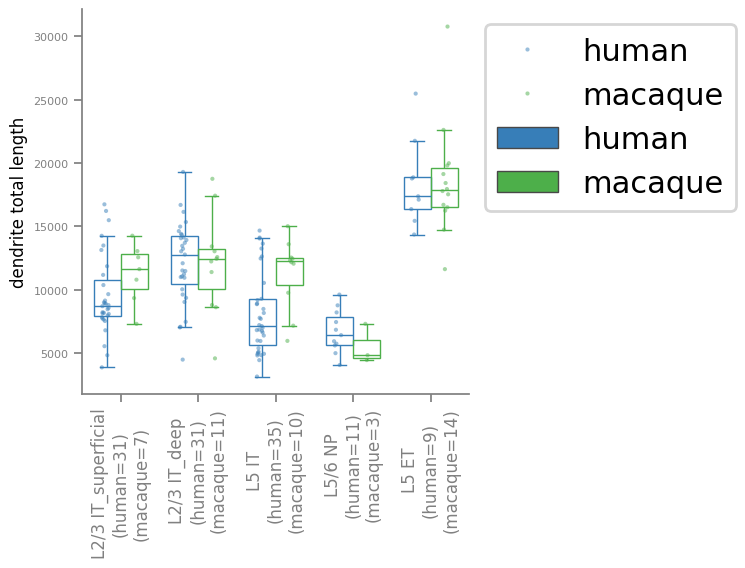

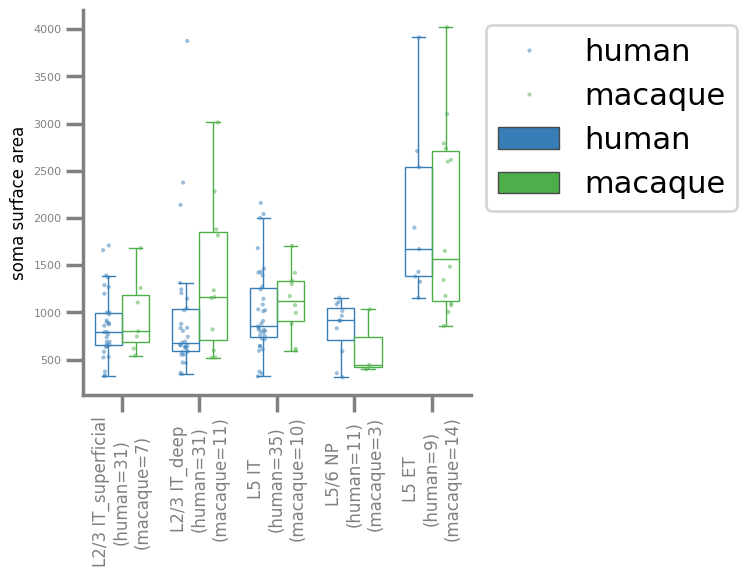

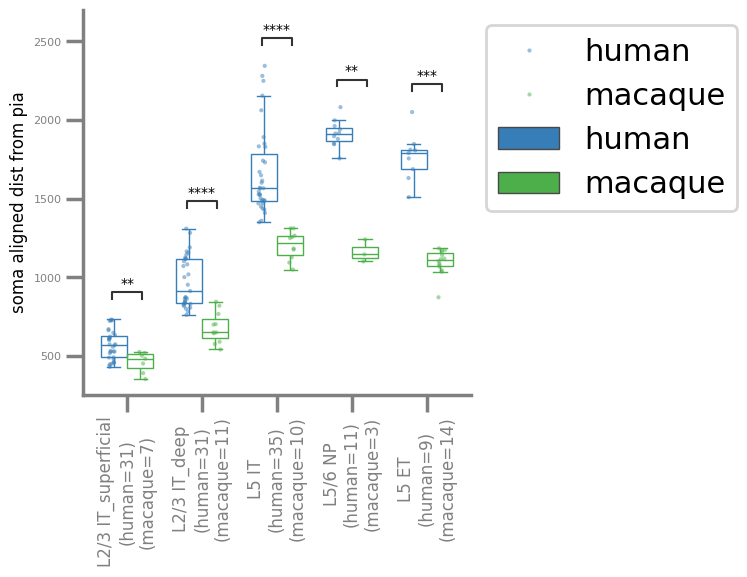

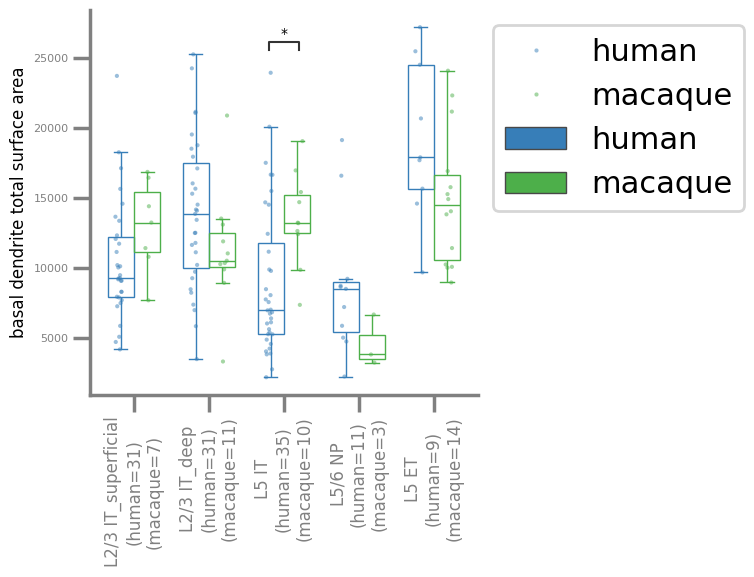

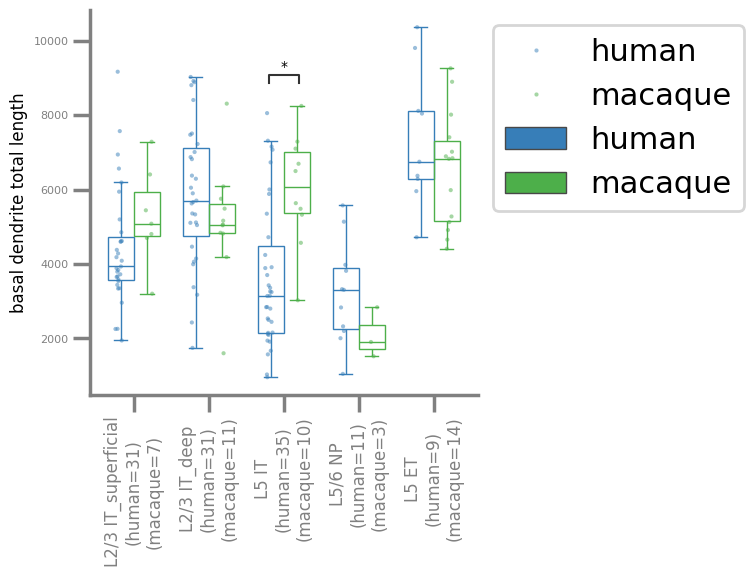

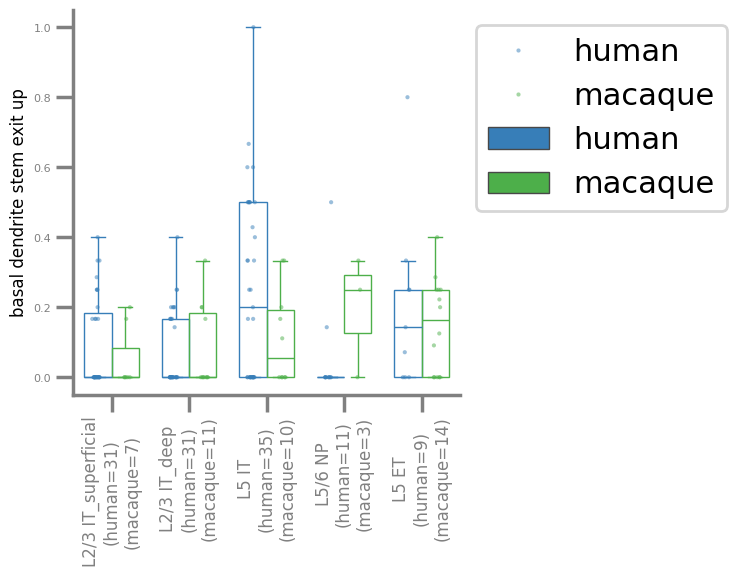

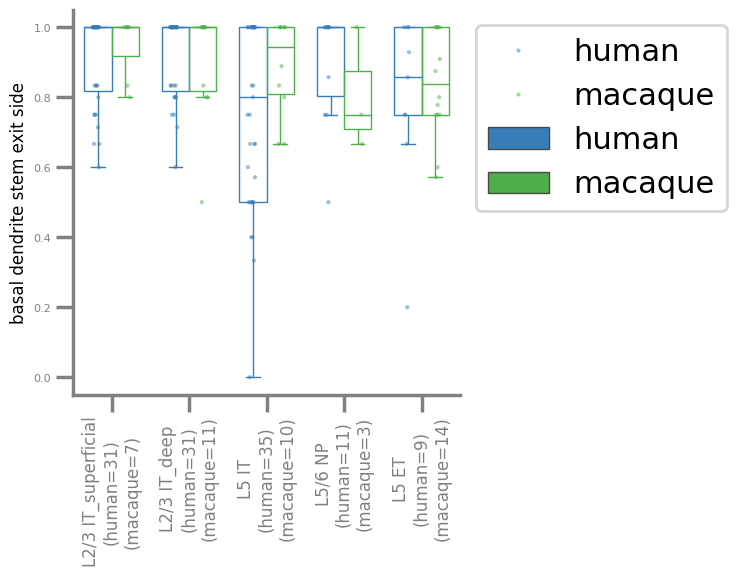

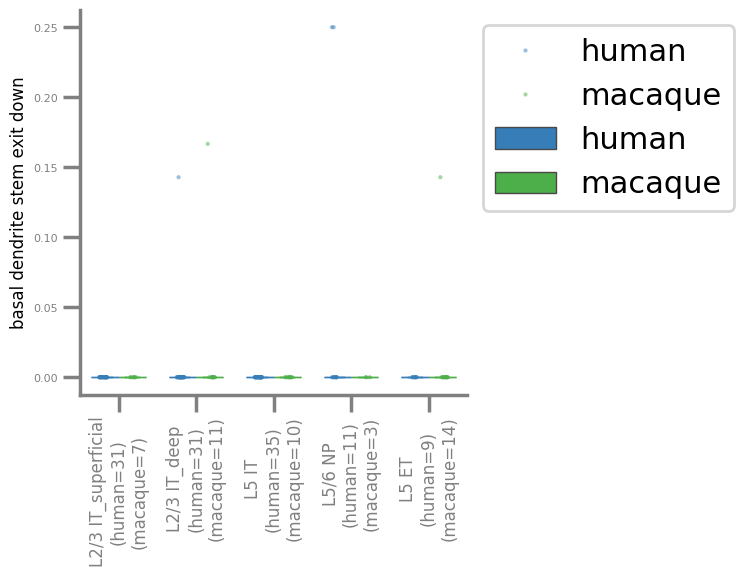

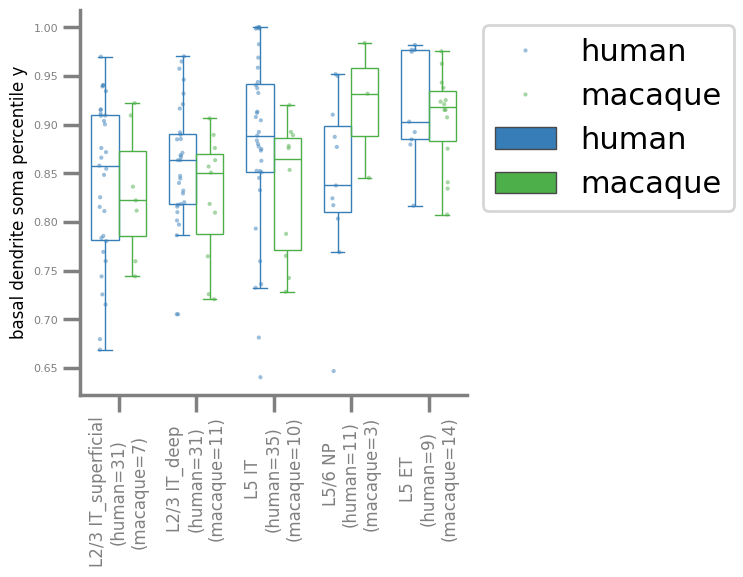

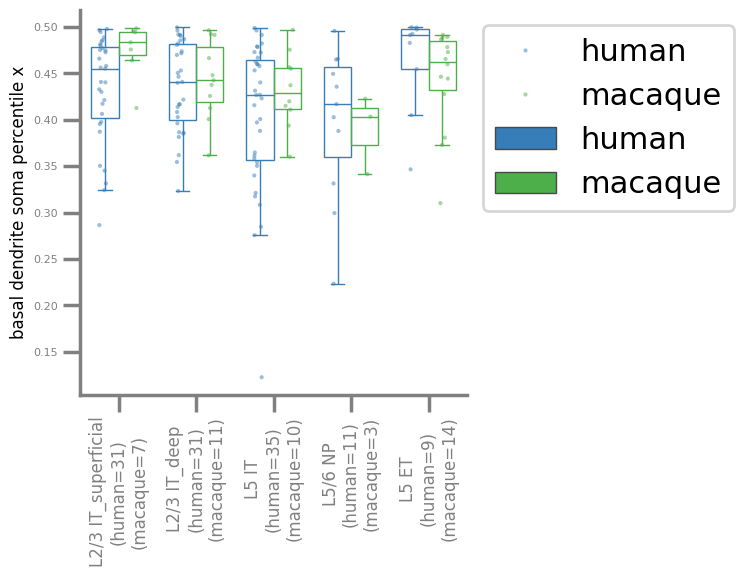

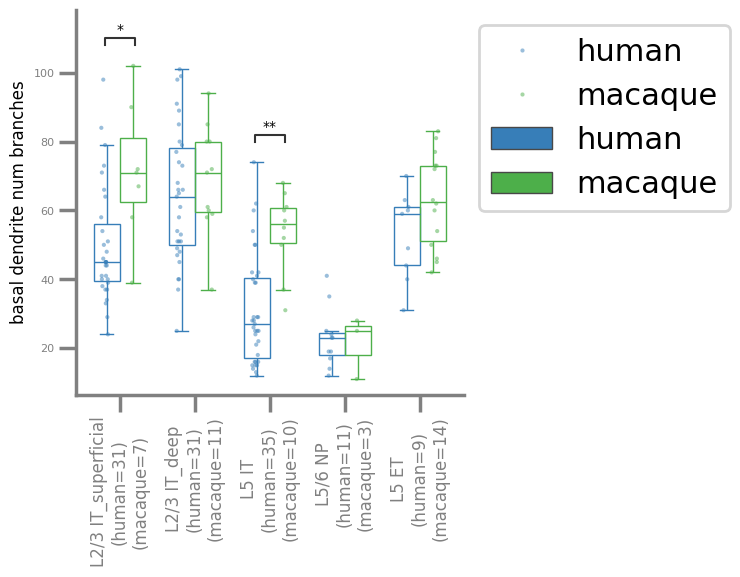

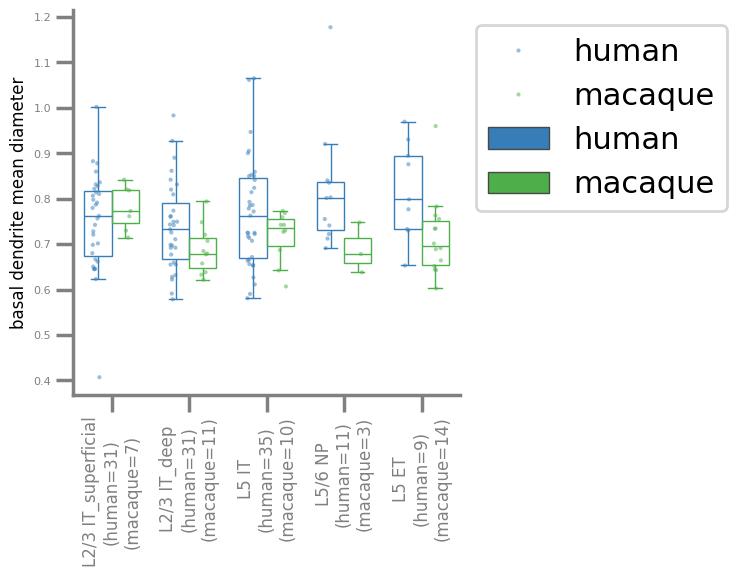

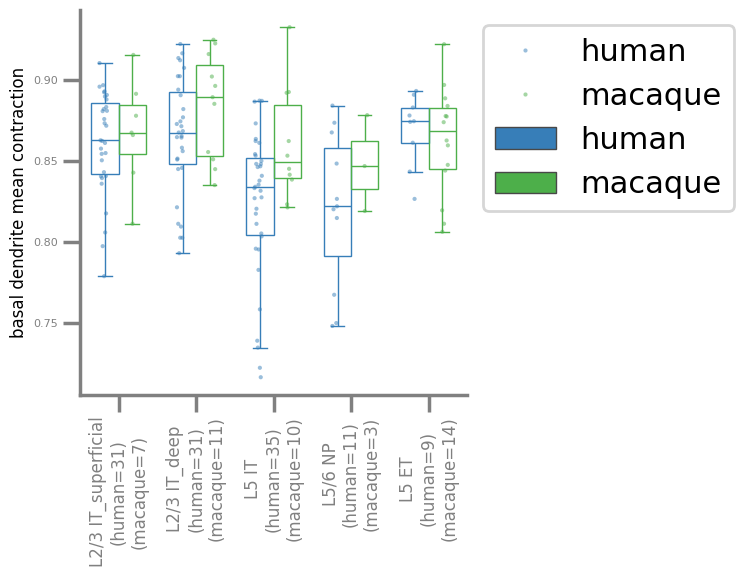

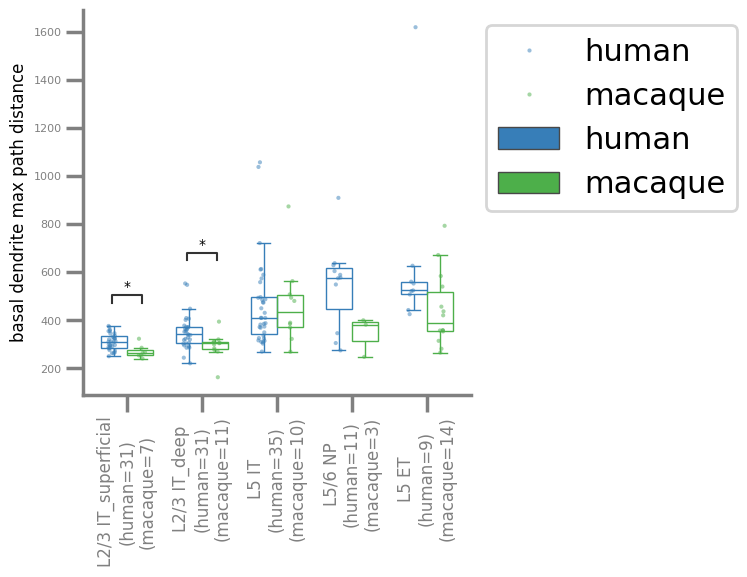

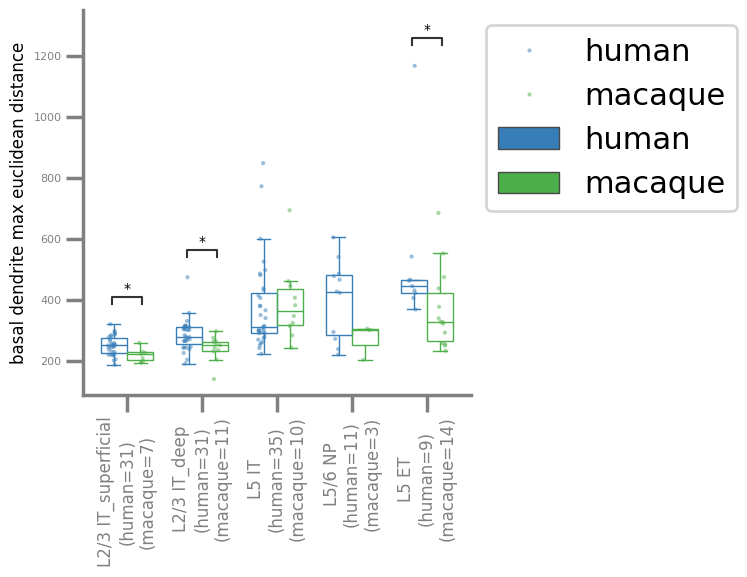

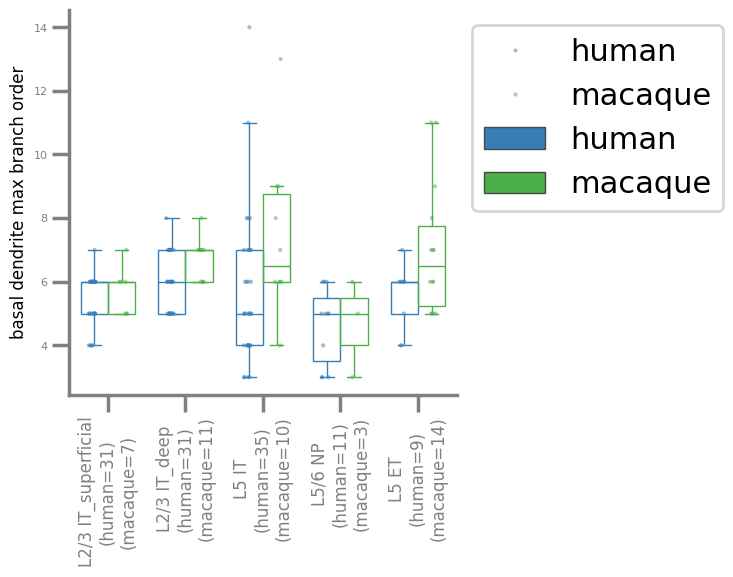

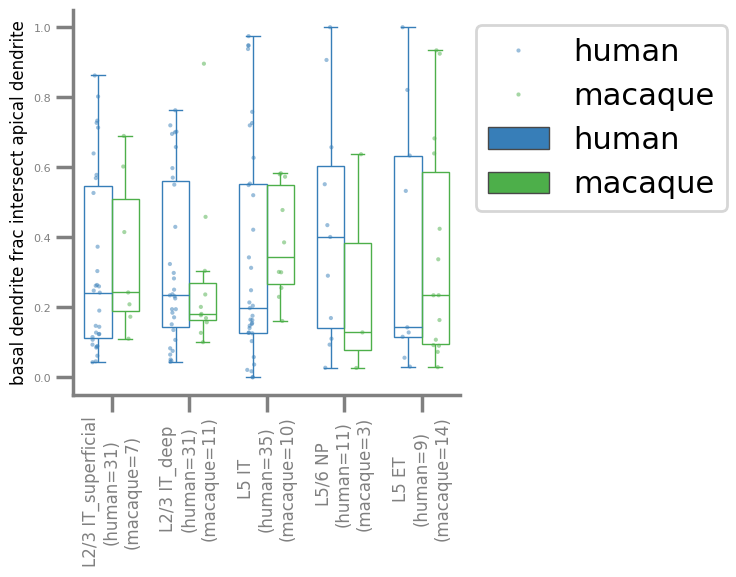

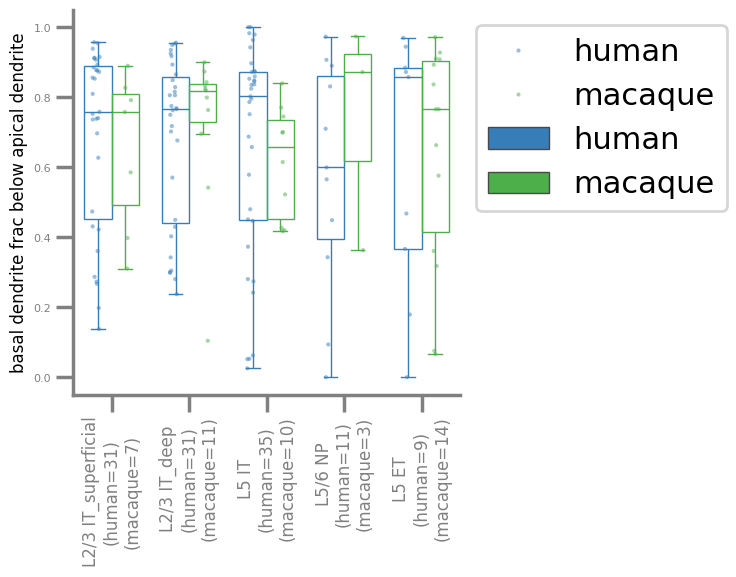

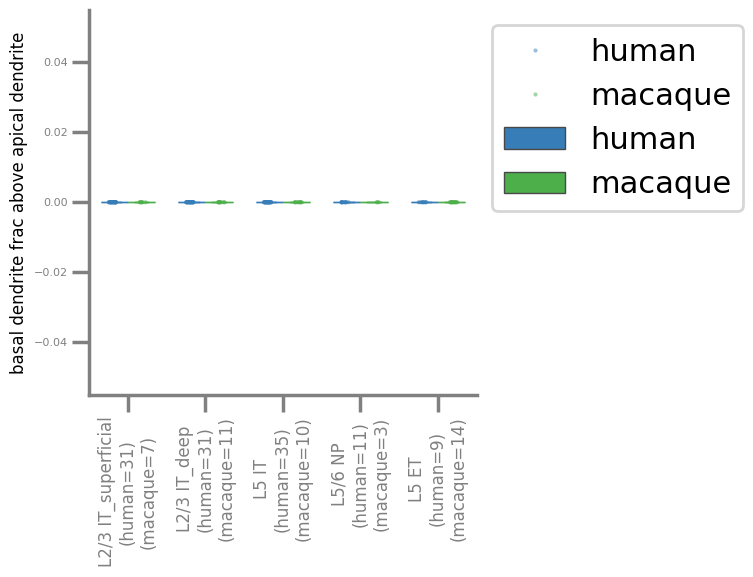

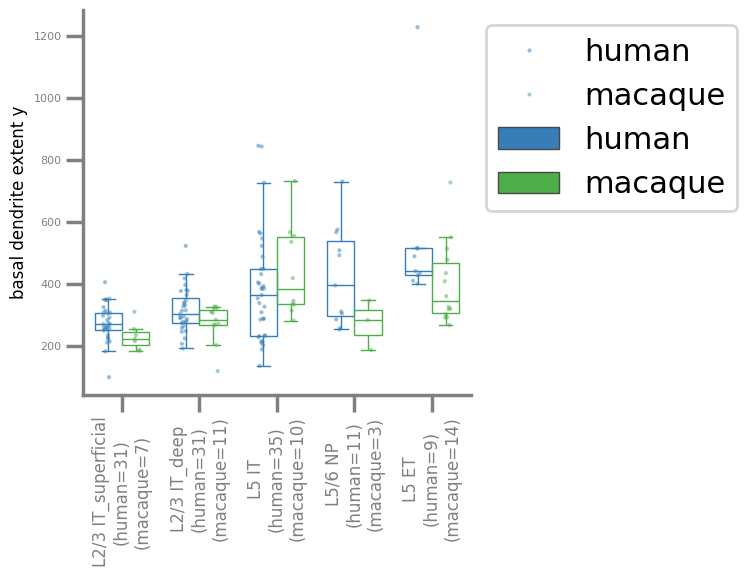

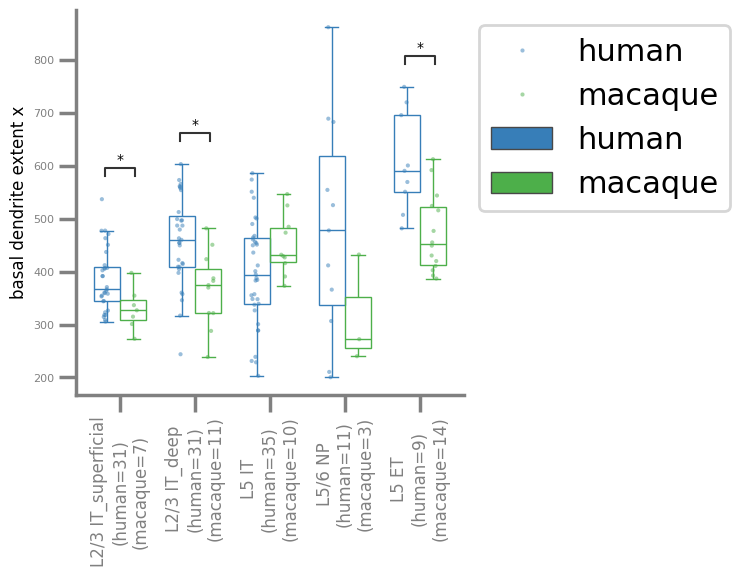

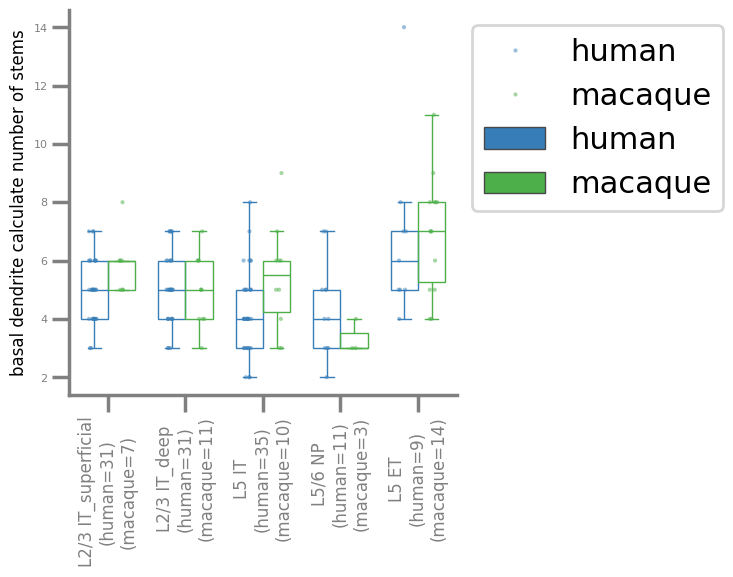

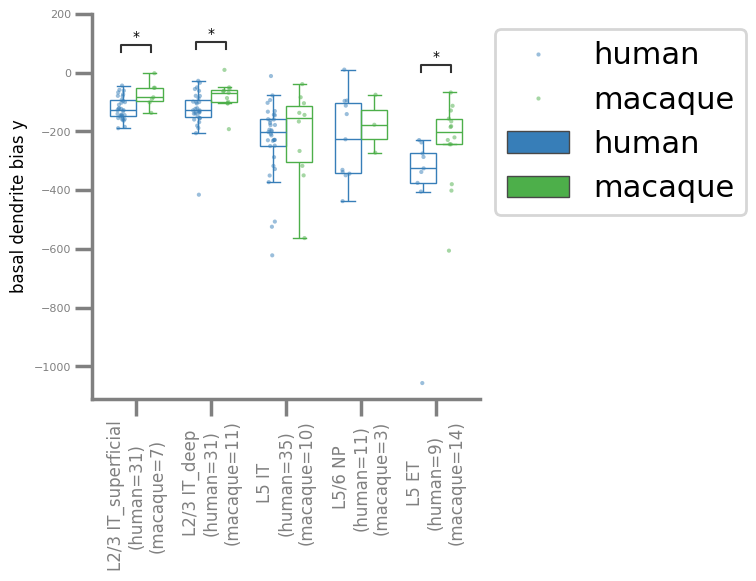

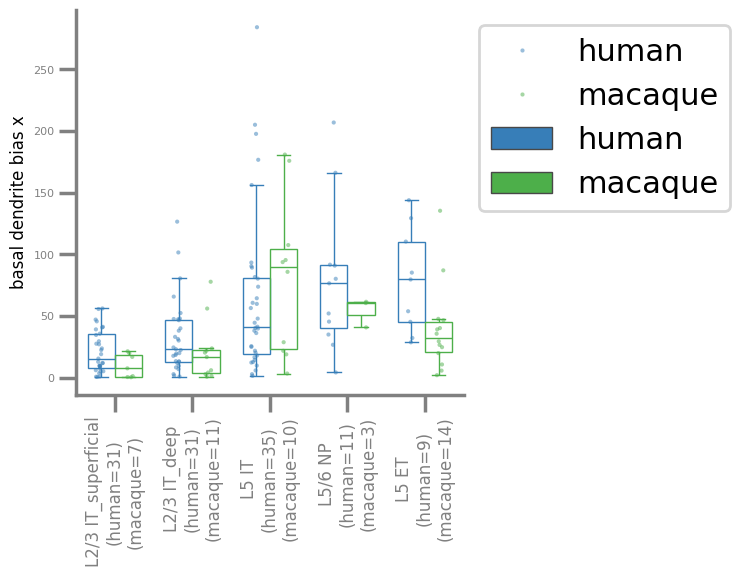

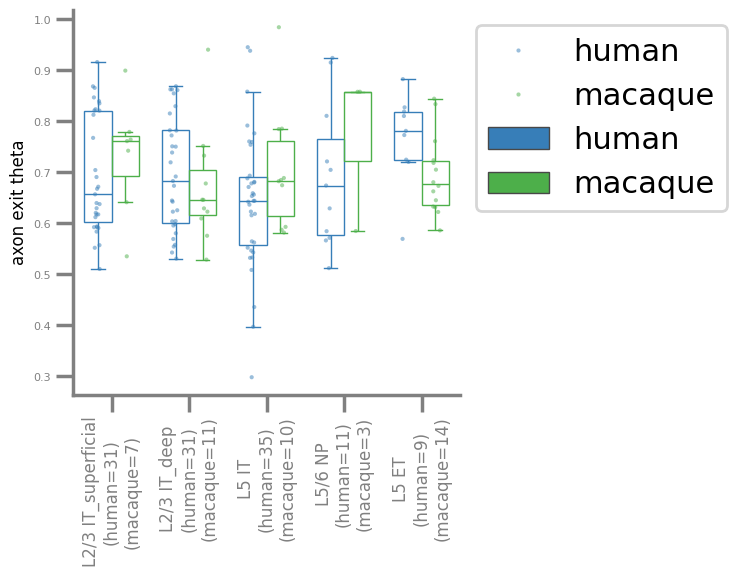

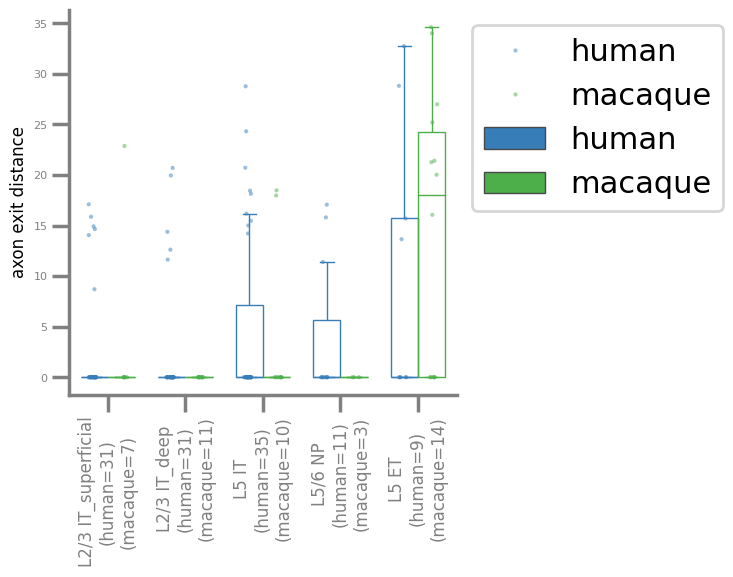

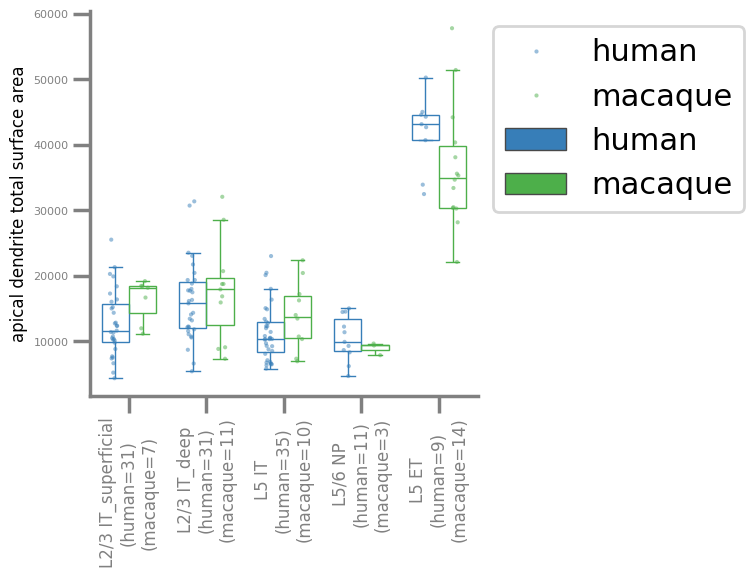

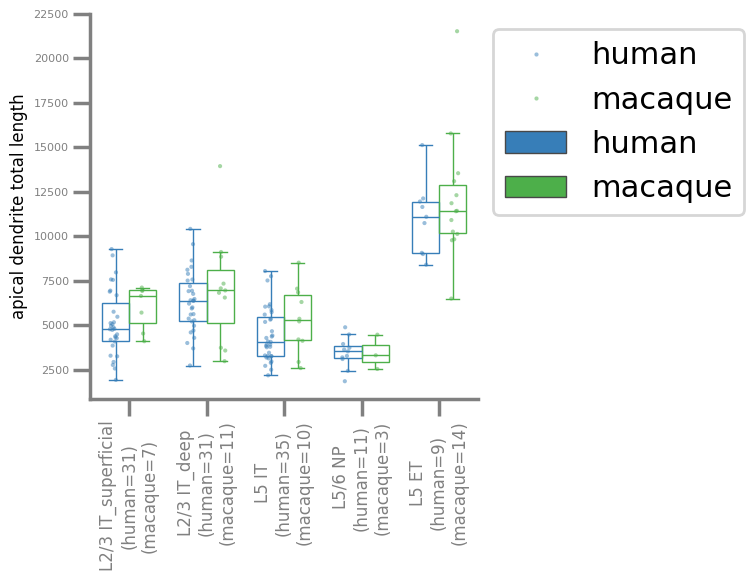

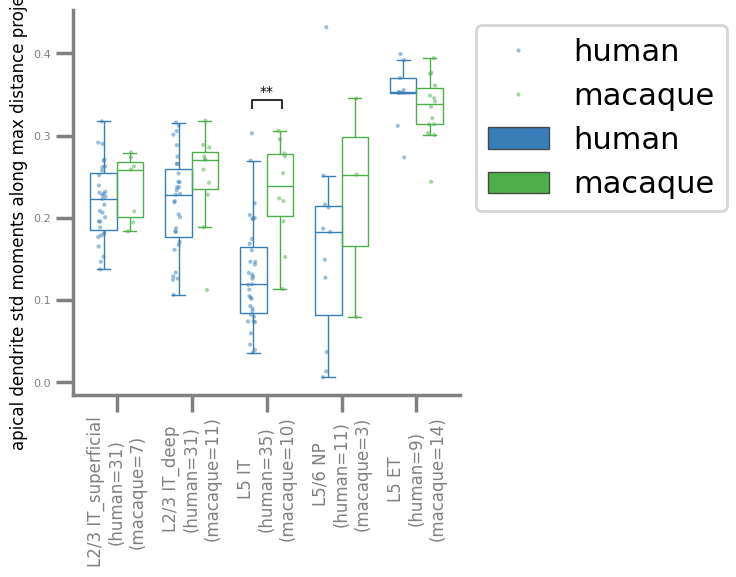

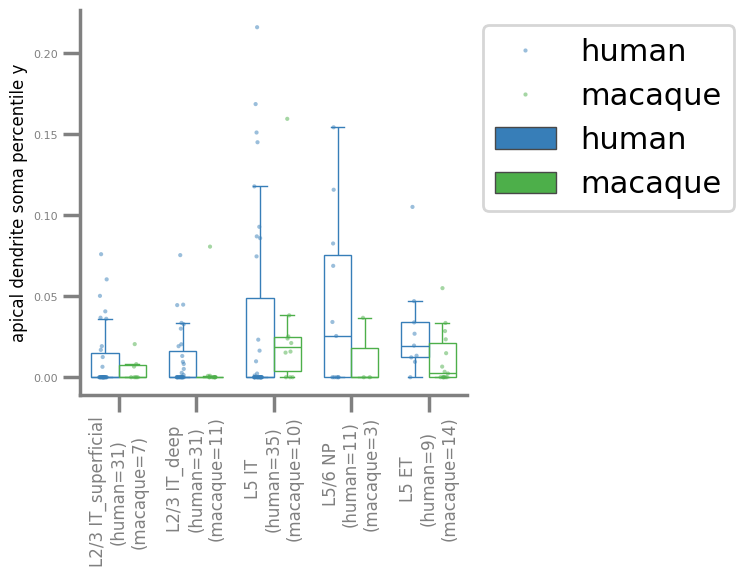

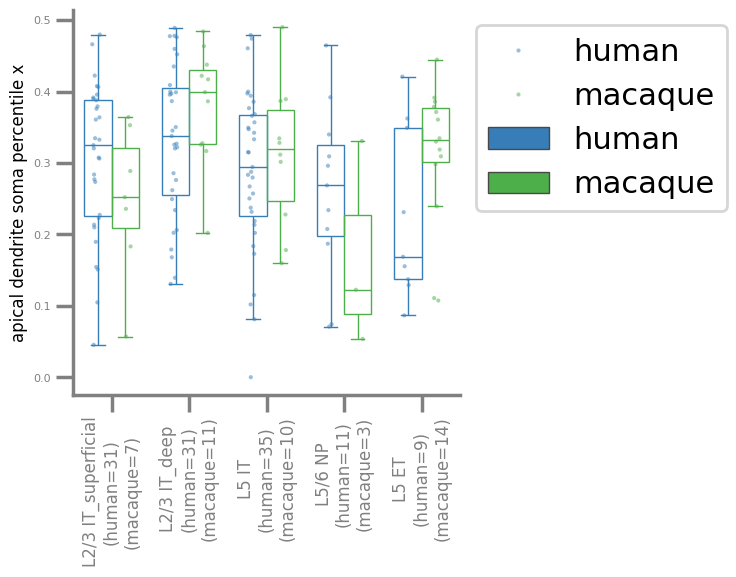

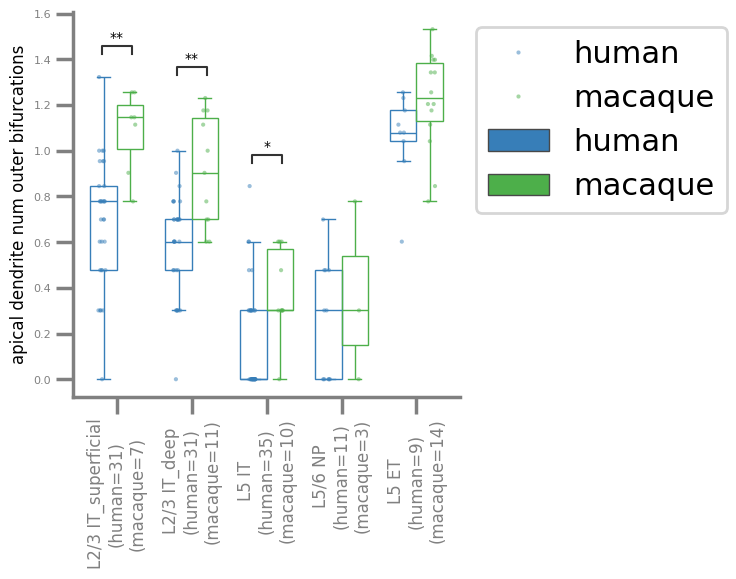

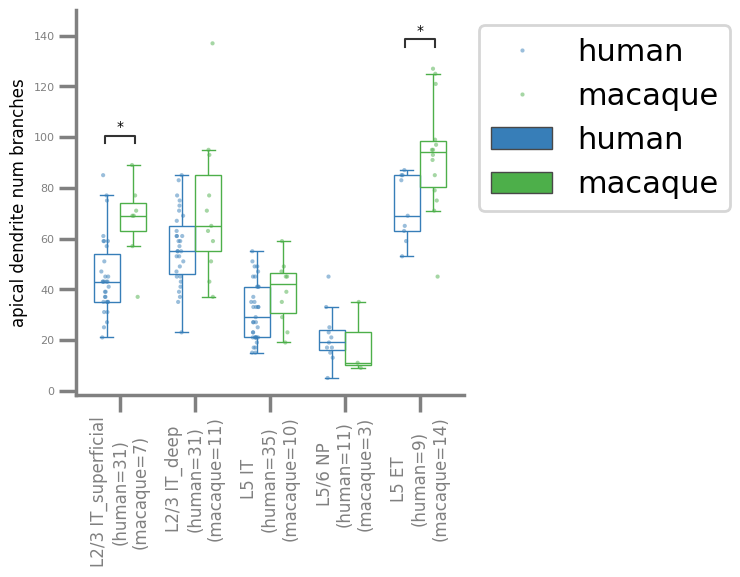

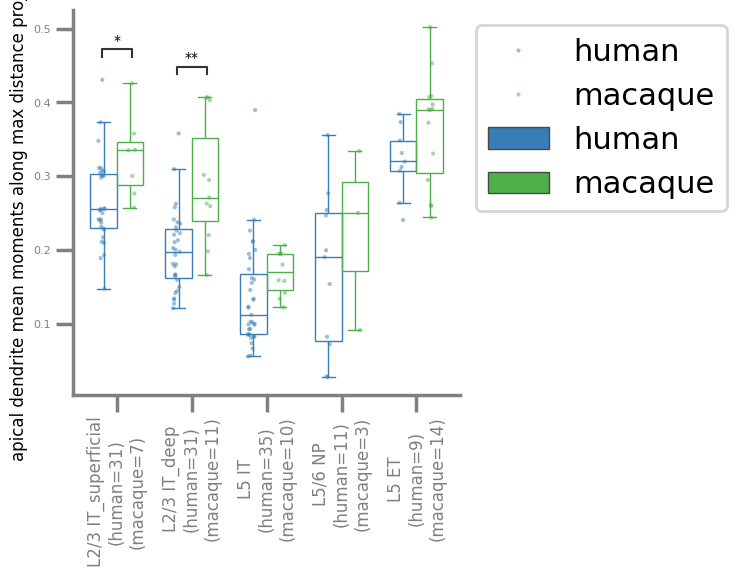

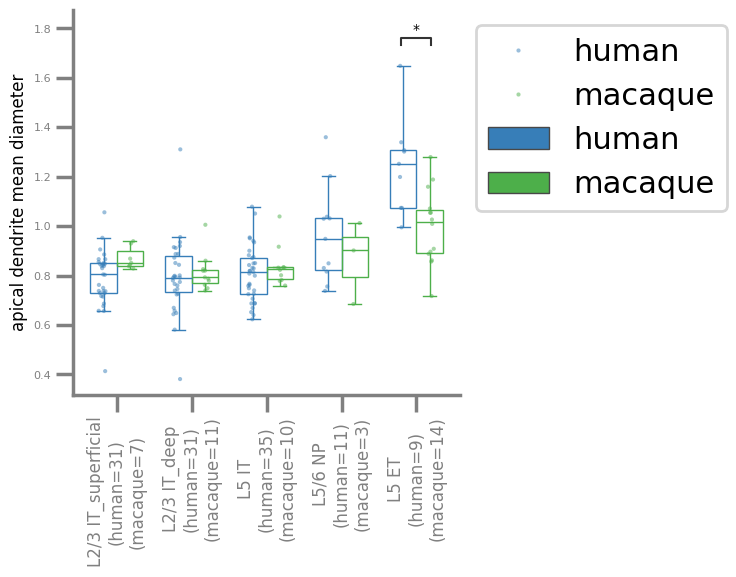

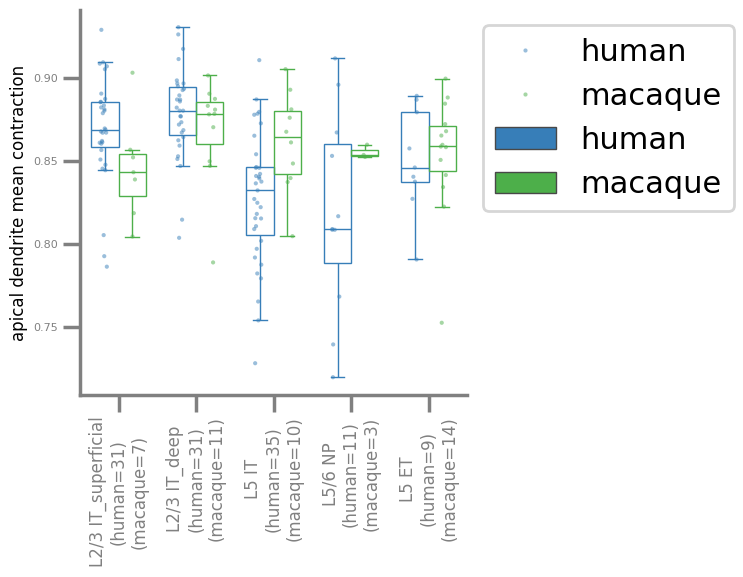

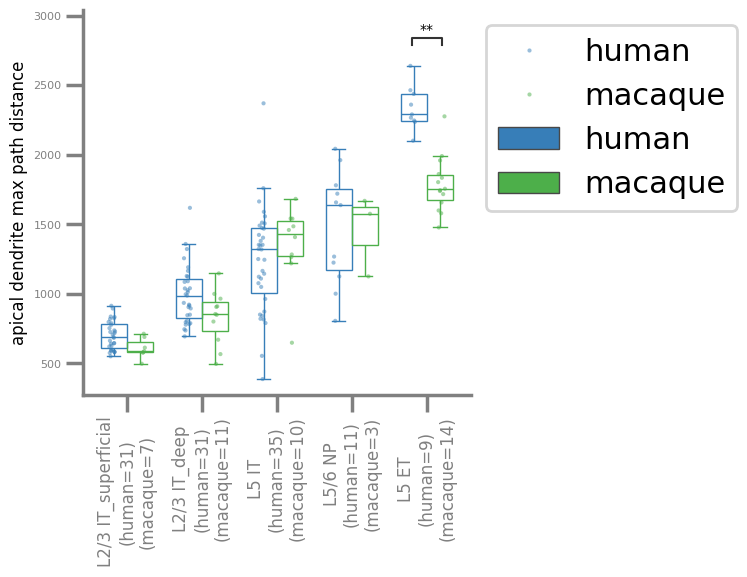

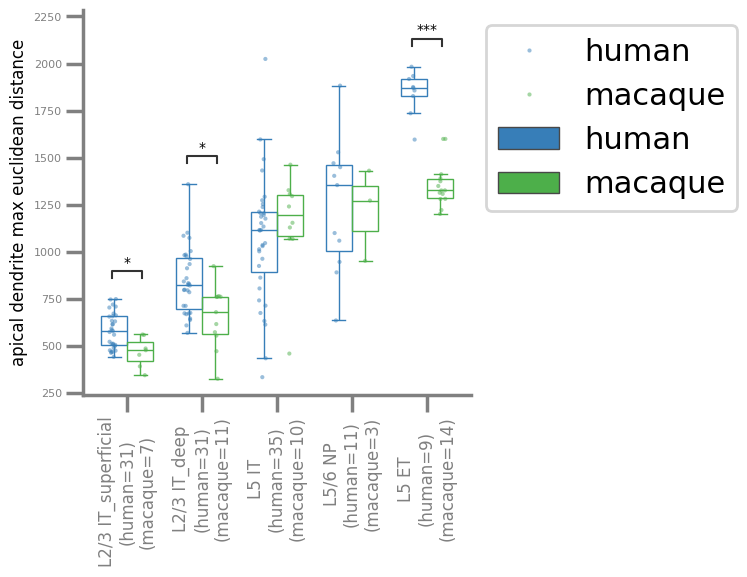

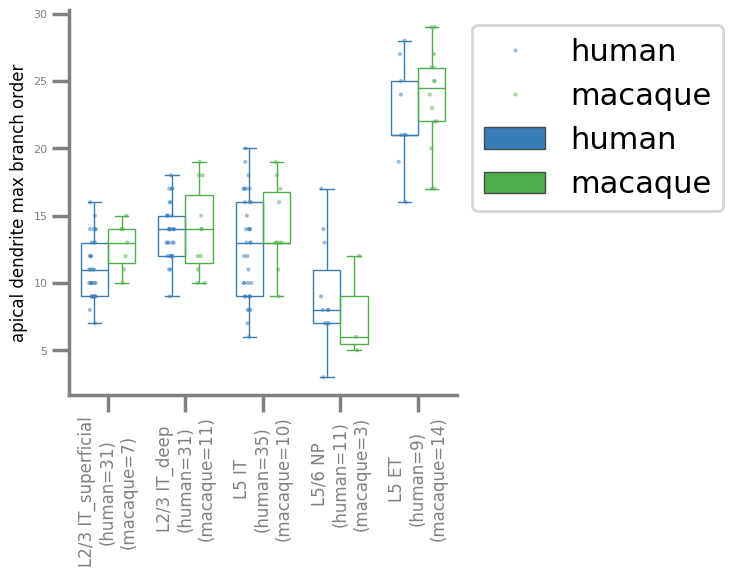

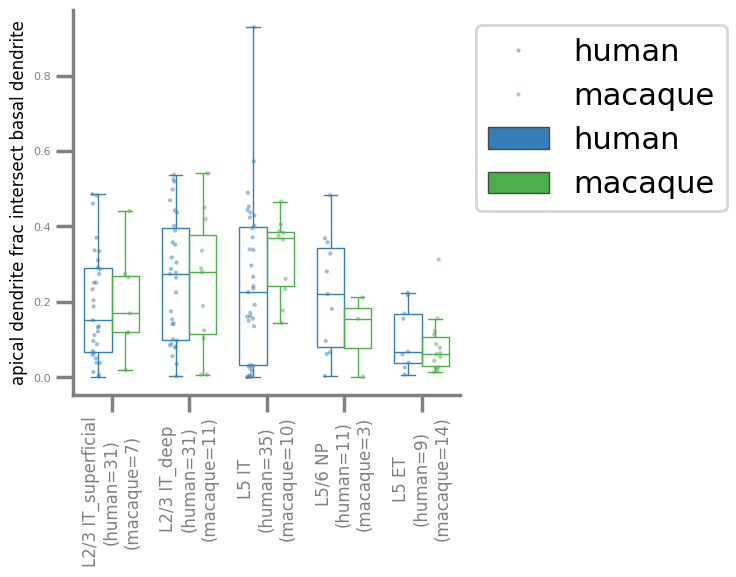

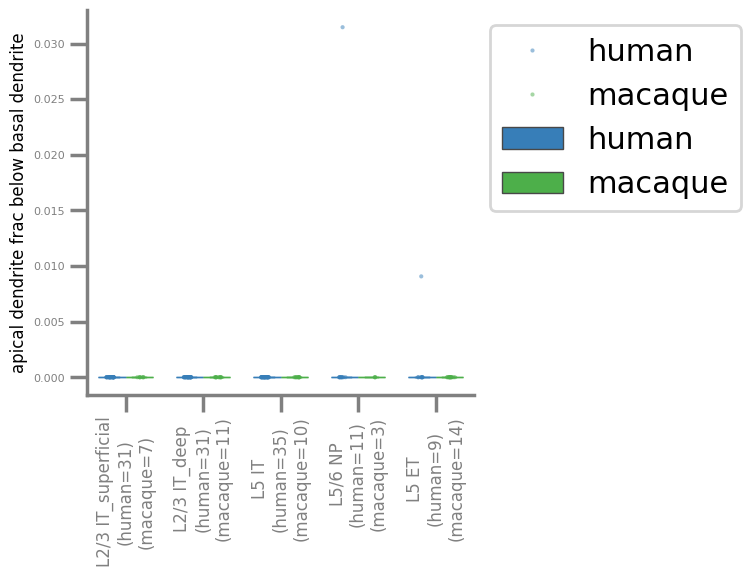

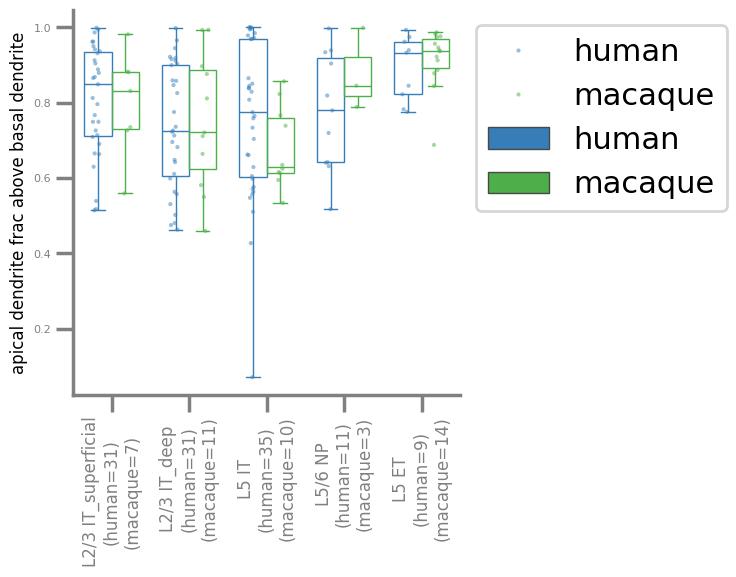

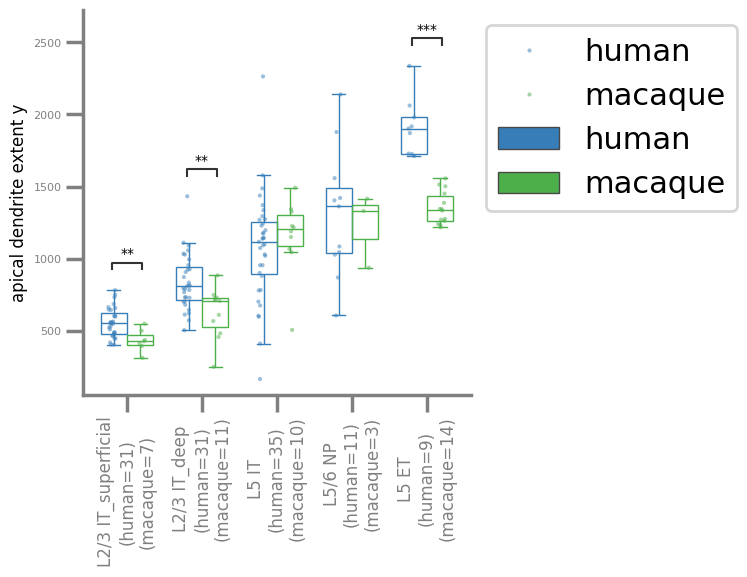

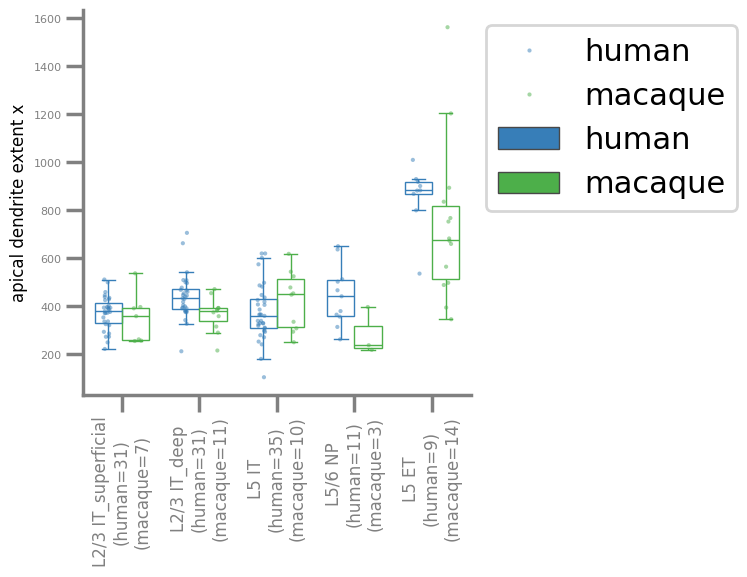

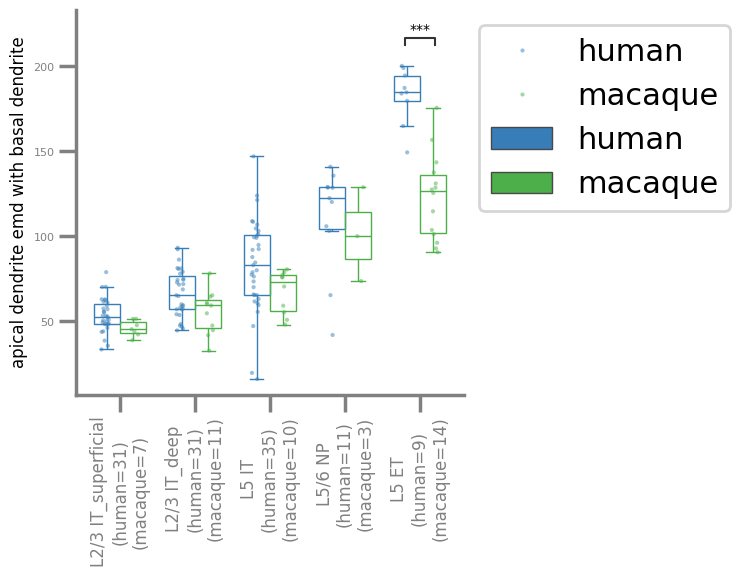

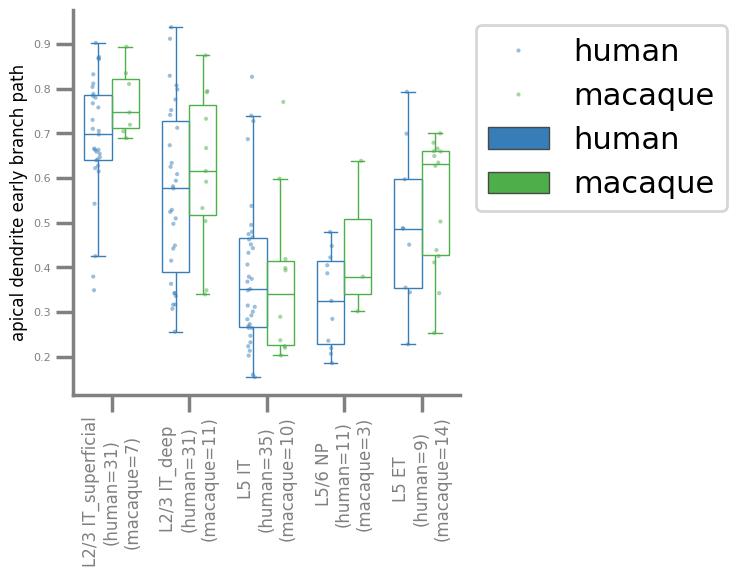

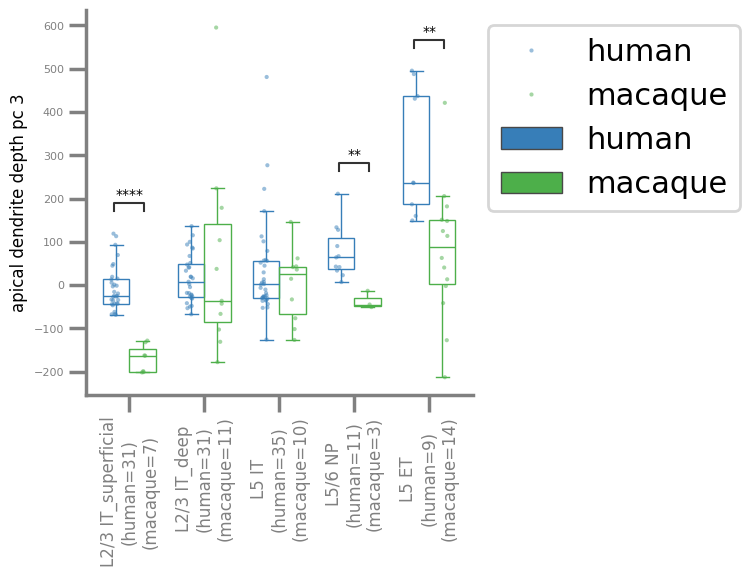

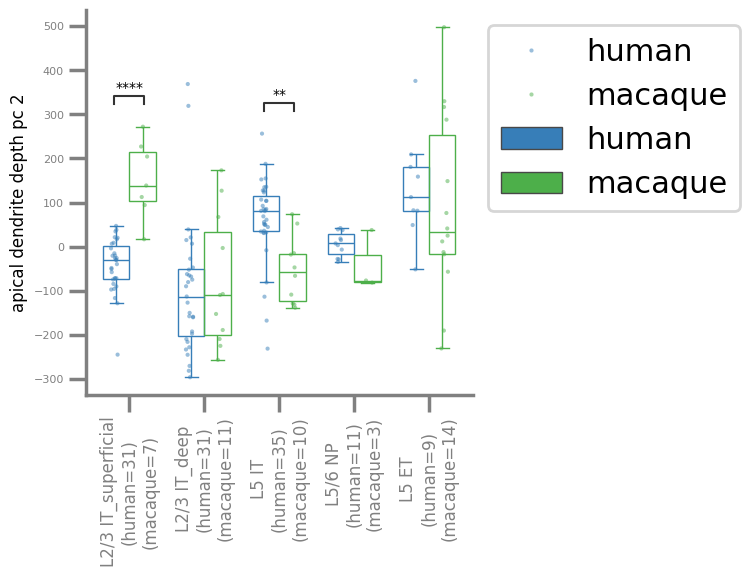

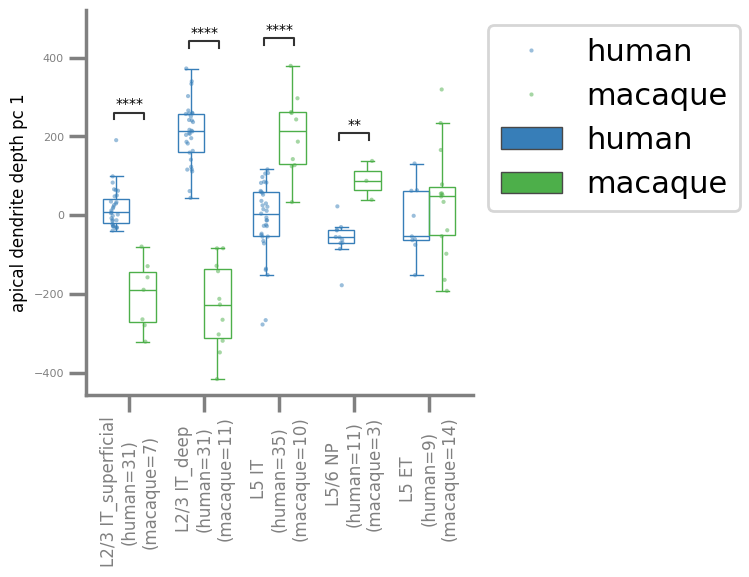

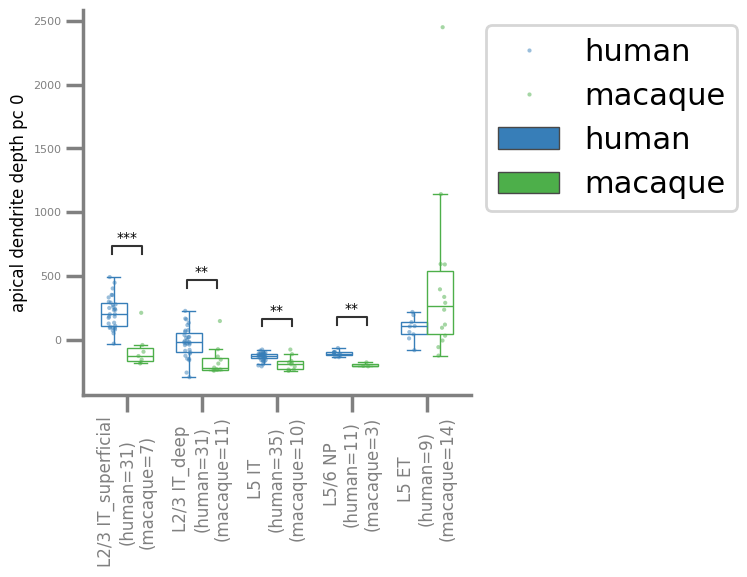

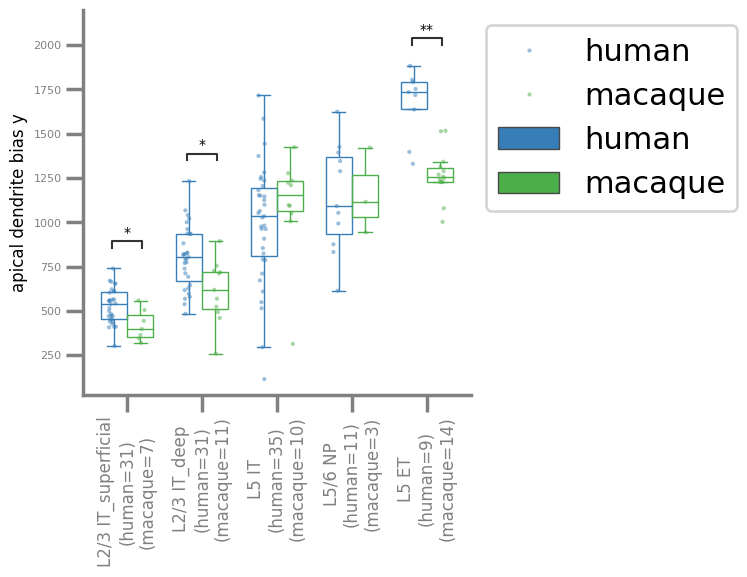

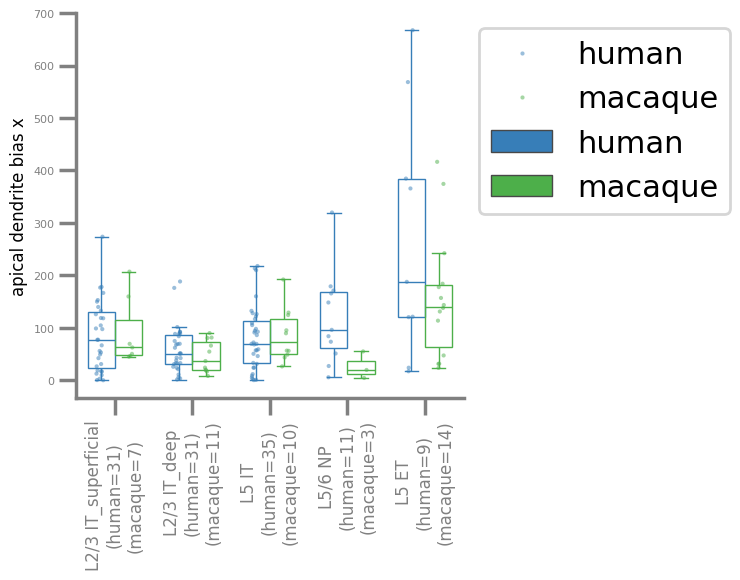

<Figure size 640x480 with 0 Axes>

In [20]:
fig_name = f'{species_type}_subclass_morpho_feature_box_plots.pdf'
if plot_stats: 
    fig_name = fig_name.replace('.pdf', '_statsAnnotated.pdf')
fig_path = os.path.join(OUT_DIR, fig_name)

features = feature_cols.copy()
with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        while features != []:
            
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=figsize,sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
            
            #grab a feature
            y_var = features.pop()

            #plot
            sns.set_context('poster')
            sns.stripplot(data=data, x=x_var, y=y_var, hue='species', palette=species_colors, order=x_var_order, alpha=0.5, dodge=True, size=3)
            sns.boxplot(data=data, x=x_var, y=y_var, hue='species', palette=species_colors, order=x_var_order, saturation=1, linewidth=1, width=box_width, showfliers = False)
            plt.legend(loc='upper left', bbox_to_anchor=(1, 1))

            # format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)
            ax.set(xlabel=None)
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=12)
            ax.tick_params(axis='x', rotation=90, labelsize=8)
            ax.tick_params(axis='y', labelsize=8)

            #add num observations per x_var
            nobs = []
            for t in x_var_order:
                nq = len(data[(data[x_var] == t) & (data.species == 'macaque')])
                nh = len(data[(data[x_var] == t) & (data.species == 'human')])
                nm = len(data[(data[x_var] == t) & (data.species == 'mouse')])
                if species_type == 'primate':
                    nobs.append(f"{t}\n(human={nh})\n(macaque={nq})")
                elif species_type == 'species':
                    nobs.append(f"{t}\n(human={nh})\n(macaque={nq})\n(mouse={nm})")
            new_x_tick_labels = [nobs[i] for i in range(len(x_var_order))]  
            ax.set_xticklabels(new_x_tick_labels, fontsize=12)


            # Add statistical annotations (only FDR-corrected significant results)
            if plot_stats:

                # Collect all subclass-level comparisons
                pairs = []
                p_values = []

                # Iterate over each subclass level
                for subclass in x_var_order:
                    # Skip if no posthoc results
                    if y_var not in mn_posthoc_pvals or subclass not in mn_posthoc_pvals[y_var]:
                        continue
                    
                    # Check if FDR-corrected main test was significant
                    if subclass not in mn_pvals_rejected[y_var] or not mn_pvals_rejected[y_var][subclass]:
                        continue

                    posthoc_results = mn_posthoc_pvals[y_var][subclass]
                    test_type = mn_test_type[y_var].get(subclass, 'none')

                    # Extract species pairs and p-values
                    for comp, pval in posthoc_results.items():
                        s1, _, s2 = comp.partition('_vs_')
                        # Skip NaNs or empty comparisons
                        if pd.isna(pval):
                            continue
                        
                        # For Mann-Whitney tests, use FDR-corrected p-value from main test
                        # For Kruskal tests, posthoc p-values are already FDR-corrected from Dunn test
                        if test_type == 'mannwhitneyu':
                            # Use FDR-corrected main test p-value
                            display_pval = mn_pvals_fdr[y_var][subclass]
                        else:
                            # Kruskal: use Dunn FDR-corrected posthoc p-value
                            display_pval = pval
                        
                        pairs.append(((subclass, s1), (subclass, s2)))
                        p_values.append(display_pval)

                # Already filtered to FDR-significant results
                if len(pairs) > 0:
                    # Temporarily reduce font size for annotations
                    original_fontsize = plt.rcParams['font.size']
                    plt.rcParams['font.size'] = 10  # smaller stars
                    # Create Annotator for grouped boxplot
                    annotator = Annotator(
                        ax,
                        pairs,
                        data=data,
                        x=x_var,
                        y=y_var,
                        hue='species',
                        order=x_var_order,
                        hue_order=[x for x in ['human', 'macaque', 'mouse'] if x in data.species.unique()],
                    )
                    annotator.configure(test=None, text_format='star', loc='inside')
                    annotator.set_pvalues(p_values)
                    annotator.annotate()

                    # Restore original font size after annotation
                    plt.rcParams['font.size'] = original_fontsize

            ax.tick_params(axis='both', colors='grey')
            ax.xaxis.set_tick_params(labelcolor='grey')
            ax.spines['bottom'].set_color('grey')
            ax.spines['left'].set_color('grey')

            fig.subplots_adjust(wspace=0, hspace=0.0)
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf()
        print()



Save stats

In [21]:
#save stats csv

rows = []

for f in feature_cols:
    for var in x_var_order:
        main_test_type = mn_test_type[f].get(var, 'none')
        raw_p = mn_pvals[f].get(var, np.nan)
        fdr_p = mn_pvals_fdr[f].get(var, np.nan)
        rejected = mn_pvals_rejected[f].get(var, False)
        posthoc = mn_posthoc_pvals[f].get(var, {})

        row = {
            'feature': f,
            'subclass': var,
            'test_type': main_test_type,
            'raw_pval': raw_p,
            'fdr_pval': fdr_p,
            'rejected': rejected,
        }

        # Add all posthoc comparisons (use FDR-adjusted if main test was significant)
        for comp in posthoc.keys():
            raw_posthoc = posthoc.get(comp, np.nan)

            if main_test_type in ['mannwhitneyu', 'kruskal'] and rejected:
                # For Kruskal, you already stored Dunn p-values with FDR correction
                # For Mann–Whitney 2-way, posthoc == main test, use FDR-adjusted main test
                fdr_posthoc = fdr_p if raw_posthoc == raw_p else raw_posthoc
                row[comp] = fdr_posthoc
            else:
                row[comp] = np.nan
        rows.append(row)

df_summary = pd.DataFrame(rows)
df_summary.to_csv(os.path.join(OUT_DIR, f'{species_type}_subclass_morpho_feature_box_plot_stats.csv'), index=False)
